<div style='background-color: #E1F5FE; border-left:4px solid #2196F3; border-radius:6px; padding:14px 18px; color:#243038;'>

<h1 style="color:#243038; margin:0.2em 0;">Modelling: predicting flight ticket prices</h1>
<p style="color:#243038; margin:0.4em 0;"><strong>LTAT.02.002 Introduction to Data Science - Autumn 2026</strong></p>
<p style="color:#243038; margin:0.4em 0;"><strong>Team members: Nazar Zavrin, Oliver Albert Hallik, Kerreth Arula</strong></p>

</div>

This notebook trains regression models that predict the ticket price of a flight from the features built in `feature_building_preprocessing.ipynb`.

**Input:** `features_sample.parquet` (10% of the flights) for fast experiments, or `features.parquet` (all 20M rows) for the final run. Switch with `USE_SAMPLE` in section 1.

**Plan of the notebook:**
1. Two simple baselines that every model has to beat.
2. Linear models (Ridge and Lasso) with a one-hot encoding + scaling pipeline.
3. A gradient boosting model (LightGBM) that uses the categorical columns directly.
4. Every model is trained twice: with and without `is_best`, because `is_best` is partly derived from the price by Google.
5. Comparison, error analysis by segment, feature importance and partial dependence plots.
6. One final evaluation on the test set.

**Rules we follow:**
- The model is trained on `log_price`, but errors are always reported in EUR (after `np.exp`), as MAE and RMSE.
- Everything that learns from data (encoders, scalers, medians, models) is fitted on the training split only.
- Hyperparameters are chosen on the validation split. The test split is used only once, at the very end.

## 1. Setup and loading

In [1]:
import sys # Run if the lightgbm import fails
print(sys.executable)
!{sys.executable} -m pip install lightgbm shap

C:\Users\kerre\anaconda3\python.exe


In [2]:
# Other imports should work, installed earlier in the course

In [24]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.inspection import permutation_importance, PartialDependenceDisplay

USE_SAMPLE = False  # True: features_sample.parquet (fast), False: features.parquet (full data)

if USE_SAMPLE:
    INPUT_FILE = Path.cwd() / "features_sample.parquet"
else:
    INPUT_FILE = Path.cwd() / "features.parquet"

RANDOM_STATE = 42
BAR_COLOR = "#2a78d6"

In [25]:
df = pd.read_parquet(INPUT_FILE)

print("Loaded file:", INPUT_FILE.name)
print(df.shape)
print(f"Memory usage: {df.memory_usage(deep=True).sum() / 1e9:.2f} GB")
df.head()

Loaded file: features.parquet
(20381571, 32)
Memory usage: 2.25 GB


,itinerary_id,flight_number,price,log_price,split,price_outlier,price_datetime,departure_date,region_from,region_to,...,emissions_per_km,dep_hour,dep_weekday,dep_month,dep_is_weekend,is_christmas,is_new_year,is_summer,search_weekday,search_hour
0,FR8257-2025-05-03-RIX-PRG,FR8257,87.989998,4.477223,train,0,2025-05-02 22:58:11.409667,2025-05-03,Baltics,Eastern,...,93.433464,9,5,5,1,0,0,0,4,22
1,BT481-2025-05-03-RIX-PRG,BT481,159.320007,5.070915,train,0,2025-05-02 22:58:11.409719,2025-05-03,Baltics,Eastern,...,108.269150,18,5,5,1,0,0,0,4,22
2,LO794-2025-05-03-RIX-WAW,LO794,222.320007,5.404118,train,0,2025-05-02 22:58:11.409754,2025-05-03,Baltics,Eastern,...,126.946564,5,5,5,1,0,0,0,4,22
3,LO782-2025-05-03-RIX-WAW,LO782,222.320007,5.404118,train,0,2025-05-02 22:58:11.409798,2025-05-03,Baltics,Eastern,...,144.983139,18,5,5,1,0,0,0,4,22
4,BT611-2025-05-03-RIX-ATH,BT611,358.320007,5.881426,train,0,2025-05-02 22:58:11.409839,2025-05-03,Baltics,Eastern,...,94.131104,14,5,5,1,0,0,0,4,22


## 2. Train / validation / test split

The split was already decided in the feature notebook and stored in the `split` column (by search date `price_datetime`):

| split | price_datetime | used for |
|---|---|---|
| `train` | before 2026-02-01 | fitting the models |
| `val` | 2026-02-01 to 2026-03-31 | choosing hyperparameters and comparing models |
| `test` | from 2026-04-01 | one final evaluation at the end |

### 2.1 Splitting the data

In [26]:
train = df[df["split"] == "train"].copy()
val = df[df["split"] == "val"].copy()
test = df[df["split"] == "test"].copy()

# The full DataFrame is not needed anymore; deleting it frees memory
del df

print(f"train: {len(train):,} rows")
print(f"val:   {len(val):,} rows")
print(f"test:  {len(test):,} rows")

train: 16,155,618 rows
val:   1,951,559 rows
test:  2,274,394 rows


### 2.2 Removing price outliers from the training data

Rows with `price_outlier == 1` (below 15 EUR or above the 99.9th percentile of train) are most likely business/first class fares or scraping errors. We remove them from the training data only, so they do not distort the fit. Validation and test keep them, because a real user would see these prices too.

In [27]:
rows_before = len(train)
train = train[train["price_outlier"] == 0].copy()

print(f"Removed {rows_before - len(train):,} outlier rows from train "
      f"({(rows_before - len(train)) / rows_before:.2%})")

Removed 30,538 outlier rows from train (0.19%)


### 2.3 Days-to-departure bucket

For the route baseline (section 5) and the error analysis (section 9) we group `days_to_departure` into five buckets. This is a fixed rule (no learning from data), so it can be applied to all three splits the same way.

In [28]:
DTD_BINS = [-1, 7, 14, 30, 60, np.inf]
DTD_LABELS = ["0-7", "8-14", "15-30", "31-60", "61+"]

for data in [train, val, test]:
    data["dtd_bucket"] = pd.cut(data["days_to_departure"], bins=DTD_BINS, labels=DTD_LABELS)

train["dtd_bucket"].value_counts().sort_index()

dtd_bucket
0-7      3258622
8-14     1893617
15-30    3804738
31-60    3823540
61+      3344563
Name: count, dtype: int64

## 3. Features and target

### 3.1 Which columns go into the model

The columns are split into groups, because the linear models and LightGBM treat them differently:

| group | columns | linear models | LightGBM |
|---|---|---|---|
| categorical | region, airline, aircraft, airports, route | one-hot encoded | used directly as categories |
| small integer "categories" | departure hour / weekday / month, search weekday / hour | one-hot encoded | used as numbers |
| numeric | distance, travel time, emissions, emissions per km, days to departure, holiday flags | scaled | used as numbers |

A linear model can only learn "price goes up by X per hour" from `dep_hour`. It cannot learn "early morning and late evening are cheaper", so for the linear models these columns are one-hot encoded. A tree model can split on any value, so for LightGBM they stay numbers.

**Not used as features** (dropped from X): `itinerary_id`, `flight_number` (identifiers, the model would memorise flights), `price`, `log_price` (the target), `split`, `price_outlier` (meta columns), and the raw timestamps `price_datetime`, `departure_date`, `departure_datetime`, `arrival_datetime` (their useful parts are already extracted as features).

`is_best` is handled separately: it is added only in the "with is_best" feature set.

In [29]:
CATEGORICAL_FEATURES = ["region_from", "region_to", "airline", "aircraft", "src", "dst", "route"]

SMALL_INTEGER_FEATURES = ["dep_hour", "dep_weekday", "dep_month", "search_weekday", "search_hour"]

NUMERIC_FEATURES = ["distance_km", "travel_time", "emissions", "emissions_per_km",
                    "days_to_departure", "dep_is_weekend", "is_christmas", "is_new_year", "is_summer"]

TARGET = "log_price"

FEATURE_SETS = ["with is_best", "without is_best"]

The two small helper functions below return the column lists for one feature set. The only difference between the two sets is `is_best`.

In [30]:
def get_numeric_columns(feature_set):
    # Numeric columns; is_best is added only in the "with is_best" set
    columns = list(NUMERIC_FEATURES)
    if feature_set == "with is_best":
        columns.append("is_best")
    return columns


def get_all_columns(feature_set):
    return CATEGORICAL_FEATURES + SMALL_INTEGER_FEATURES + get_numeric_columns(feature_set)


print("Columns with is_best:   ", len(get_all_columns("with is_best")))
print("Columns without is_best:", len(get_all_columns("without is_best")))

Columns with is_best:    22
Columns without is_best: 21


### 3.2 Check that no column is missing

A quick check that every feature column exists in the file. If this fails, the feature notebook probably has to be re-run.

In [31]:
for column in get_all_columns("with is_best") + [TARGET, "price"]:
    if column not in train.columns:
        print(f"Column {column} is missing from {INPUT_FILE.name}")

print("All feature columns found.")

All feature columns found.


### 3.3 X and y

`X_*` holds all feature columns (including `is_best`). Each model selects the columns of its feature set from it. `y_*` is the target `log_price`. `price_*` is the price in EUR, which is used to compute the errors.

In [32]:
ALL_COLUMNS = get_all_columns("with is_best")

X_train = train[ALL_COLUMNS]
X_val = val[ALL_COLUMNS]
X_test = test[ALL_COLUMNS]

y_train = train[TARGET]
y_val = val[TARGET]

price_train = train["price"].to_numpy()
price_val = val["price"].to_numpy()
price_test = test["price"].to_numpy()

print("X_train:", X_train.shape)
print("X_val:  ", X_val.shape)
print("X_test: ", X_test.shape)

X_train: (16125080, 22)
X_val:   (1951559, 22)
X_test:  (2274394, 22)


## 4. Evaluation

Every model predicts `log_price`. To get a price in EUR back, we apply `np.exp` to the prediction. Then we compute two errors:

- **MAE** (mean absolute error): on average, how many EUR the prediction is off.
- **RMSE** (root mean squared error): punishes large errors more, so it is sensitive to the expensive tickets.

All results are collected in the list `results`, which becomes the comparison table in section 8.

In [33]:
results = []


def add_result(model_name, feature_set, split_name, true_price, predicted_price):
    # Computes MAE and RMSE in EUR and stores them in the results list
    mae = mean_absolute_error(true_price, predicted_price)
    rmse = np.sqrt(mean_squared_error(true_price, predicted_price))
    results.append({
        "model": model_name,
        "feature set": feature_set,
        "split": split_name,
        "MAE (EUR)": round(mae, 2),
        "RMSE (EUR)": round(rmse, 2),
    })
    print(f"{model_name} {feature_set} {split_name}  MAE {mae:.2f}   RMSE {rmse:.2f}")

## 5. Baselines

A model is only useful if it is better than a very simple rule. Baselines do not use `is_best`.

### 5.1 Global median

Predict the median training price for every flight.

In [34]:
global_median = np.median(price_train)
print(f"Global median price in train: {global_median:.2f} EUR")

add_result("Baseline: global median", "none", "val",
           price_val, np.full(len(price_val), global_median))

Global median price in train: 143.69 EUR
Baseline: global median none val  MAE 146.97   RMSE 348.28


### 5.2 Median per route and days-to-departure bucket

A smarter rule: predict the median training price of flights on the same route that were searched a similar number of days before departure. This uses the two things a traveller would look at first.

Some combinations of route and bucket do not exist in train. For those we fall back to the route median, and if the route is new as well, to the global median.

In [35]:
route_bucket_median = (
    train.groupby(["route", "dtd_bucket"], observed=True)["price"]
    .median()
    .reset_index()
    .rename(columns={"price": "route_bucket_median"})
)

route_median = (
    train.groupby("route", observed=True)["price"]
    .median()
    .reset_index()
    .rename(columns={"price": "route_median"})
)

print("Route x bucket combinations in train:", len(route_bucket_median))
print("Routes in train:", len(route_median))
route_bucket_median.head()

Route x bucket combinations in train: 5021
Routes in train: 1079


,route,dtd_bucket,route_bucket_median
0,AMS-ARN,0-7,370.230011
1,AMS-ARN,8-14,265.230011
2,AMS-ARN,15-30,199.330002
3,AMS-ARN,31-60,165.229996
4,AMS-ARN,61+,165.080002


The function below looks up the medians for a split and fills the gaps step by step (route x bucket -> route -> global).

In [36]:
def predict_route_bucket_baseline(data):
    lookup = data[["route", "dtd_bucket"]].copy()
    lookup = lookup.merge(route_bucket_median, on=["route", "dtd_bucket"], how="left")
    lookup = lookup.merge(route_median, on="route", how="left")

    prediction = lookup["route_bucket_median"]
    prediction = prediction.fillna(lookup["route_median"])
    prediction = prediction.fillna(global_median)

    missing_bucket = lookup["route_bucket_median"].isna().mean()
    print(f"Rows that needed a fallback: {missing_bucket:.2%}")
    return prediction.to_numpy()


baseline_val_prediction = predict_route_bucket_baseline(val)
add_result("Baseline: route x days bucket", "none", "val", price_val, baseline_val_prediction)

Rows that needed a fallback: 0.11%
Baseline: route x days bucket none val  MAE 84.25   RMSE 229.24


## 6. Linear models: Ridge and Lasso

### 6.1 Preprocessing pipeline

Linear models need numbers, and they work best when the numbers are on a similar scale. The pipeline has two steps:

1. A `ColumnTransformer` that treats each column group differently:
   - numeric columns -> `StandardScaler`: subtract the train mean and divide by the train standard deviation, so every numeric feature has mean 0 and standard deviation 1. Without this, the penalty in Ridge/Lasso would punish features with small units (like `is_summer`) much more than features with big units (like `distance_km`).
   - categorical and small integer columns -> `OneHotEncoder`: one 0/1 column per value. `handle_unknown="ignore"` means a value that never appeared in train simply gets all zeros instead of an error. The result is a sparse matrix: only the 1s are stored. With about 1,300 one-hot columns and millions of rows, a normal (dense) matrix would not fit in memory.
2. The model itself (Ridge or Lasso).

Putting both into one `Pipeline` guarantees that the scaler and encoder are fitted on the training data only, and that validation and test data are transformed in exactly the same way.

In [37]:
def make_linear_pipeline(model, feature_set):
    preprocess = ColumnTransformer([
        ("numeric", StandardScaler(), get_numeric_columns(feature_set)),
        ("onehot", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL_FEATURES + SMALL_INTEGER_FEATURES),
    ])
    pipeline = Pipeline([
        ("preprocess", preprocess),
        ("model", model),
    ])
    return pipeline

The dictionaries below store, for every model and feature set, the best fitted model and its validation predictions. The key is like `"Ridge (with is_best)"`. They are used in all later sections.

In [38]:
best_models = {}
val_predictions = {}

### 6.2 Ridge

Ridge is linear regression with an L2 penalty: large coefficients are punished, which keeps the model stable when features are correlated (like distance, travel time and emissions). The strength of the penalty is `alpha`.

We try a few values of `alpha` for each feature set and keep the one with the lowest validation MAE.

**Sample run**: we ran the training and validation with the sample first, testing alphas in [0, 0.1, 1, 10, 100, 1000, 3000, 5000, 10000]. We concluded, that with is_best, the best alpha was 3000, and 5000 without. The output of the sample run:<br>

Ridge  with is_best alpha=0  val MAE 87.17<br>
Ridge  with is_best alpha=3000  val MAE 86.48<br>
Ridge  with is_best alpha=5000  val MAE 86.49<br>
Ridge  with is_best alpha=10000  val MAE 86.75<br>
Best alpha for Ridge (with is_best): 3000<br>

Ridge  without is_best alpha=0  val MAE 88.28<br>
Ridge  without is_best alpha=3000  val MAE 87.46<br>
Ridge  without is_best alpha=5000  val MAE 87.37<br>
Ridge  without is_best alpha=10000  val MAE 87.51<br>
Best alpha for Ridge (without is_best): 5000<br>

For the full run, the alpha is probably larger, so we will start at 3000 and try even bigger alphas for both the feature sets.

In [39]:
RIDGE_ALPHAS = [3000, 10000, 30000, 100000]

for feature_set in FEATURE_SETS:
    best_mae = np.inf

    for alpha in RIDGE_ALPHAS:
        pipeline = make_linear_pipeline(Ridge(alpha=alpha), feature_set)
        pipeline.fit(X_train, y_train)

        predicted_price = np.exp(pipeline.predict(X_val))
        mae = mean_absolute_error(price_val, predicted_price)
        print(f"Ridge  {feature_set:} alpha={alpha:}  val MAE {mae:.2f}")

        if mae < best_mae:
            best_mae = mae
            best_alpha = alpha
            best_pipeline = pipeline
            best_prediction = predicted_price

    key = f"Ridge ({feature_set})"
    best_models[key] = best_pipeline
    val_predictions[key] = best_prediction
    print(f"Best alpha for {key}: {best_alpha}\n")

Ridge  with is_best alpha=3000  val MAE 86.29
Ridge  with is_best alpha=10000  val MAE 86.25
Ridge  with is_best alpha=30000  val MAE 86.29
Ridge  with is_best alpha=100000  val MAE 86.71
Best alpha for Ridge (with is_best): 10000

Ridge  without is_best alpha=3000  val MAE 87.50
Ridge  without is_best alpha=10000  val MAE 87.42
Ridge  without is_best alpha=30000  val MAE 87.27
Ridge  without is_best alpha=100000  val MAE 87.45
Best alpha for Ridge (without is_best): 30000



In [40]:
for feature_set in FEATURE_SETS:
    key = f"Ridge ({feature_set})"
    add_result("Ridge", feature_set, "val", price_val, val_predictions[key])

Ridge with is_best val  MAE 86.25   RMSE 219.84
Ridge without is_best val  MAE 87.27   RMSE 221.49


### 6.3 Lasso

Lasso uses an L1 penalty instead. It sets the coefficients of unhelpful features to exactly zero, so it also performs feature selection. In section 10.2 we look at which features it removed.

**IMPORTANT** - Lasso took hours to even make a few predictions on the small sample dataset, and even then the MAE was not better than Ridge. We decided not to re-train lasso on the full dataset, because it would probably take days. If replicating the work in this notebook, keep this in mind. The output of lasso on the sample was left here just to show we tried. We will not compare lasso, but will see which

**Output of lasso on sample set:** <br>
Lasso  with is_best alpha=5e-06  val MAE 86.98<br>
Lasso  with is_best alpha=3e-05  val MAE 86.55<br>
Lasso  with is_best alpha=0.0001  val MAE 86.56<br>
Best alpha for Lasso (with is_best): 3e-05

We will run lasso only once with one alpha, because it would take too much to tune and we saw on the sample set that it was not worth it.

In [41]:
pipeline = make_linear_pipeline(Lasso(alpha=0.001, max_iter=2000), "without is_best")
pipeline.fit(X_train, y_train)

predicted_price = np.exp(pipeline.predict(X_val))
mae = mean_absolute_error(price_val, predicted_price)
print(f"Lasso without is_best alpha=0.001  val MAE {mae:.2f}")
key = f"Lasso (without is_best)"
best_models[key] = pipeline
val_predictions[key] = predicted_price

Lasso without is_best alpha=0.001  val MAE 88.98


In [42]:
add_result("Lasso", "without is_best", "val", price_val, val_predictions["Lasso (without is_best)"])

Lasso without is_best val  MAE 88.98   RMSE 226.20


## 7. LightGBM

LightGBM builds many small decision trees one after another; each new tree corrects the errors of the previous ones. Compared to the linear models:

- it can learn non-linear effects and interactions without us creating them by hand;
- it uses the `category` columns directly (no one-hot encoding needed), and it does not need scaling.

Early stopping: we allow up to 5,000 trees, but after every tree LightGBM checks the error on the validation set. If it has not improved for 100 trees, training stops and the best number of trees is kept. This is how the number of trees is tuned on the validation set.

The other settings are reasonable defaults for a large data set and were not tuned:
- `learning_rate=0.05`: how big a step each tree takes (smaller = more trees, usually a bit better);
- `num_leaves=127`: how complex one tree can be;
- `min_child_samples=100`: a leaf needs at least 100 rows, which prevents learning from a handful of flights.

For the sample run, LightGBM stopped at around 1400 trees

In [43]:
for feature_set in FEATURE_SETS:
    columns = get_all_columns(feature_set)

    model = lgb.LGBMRegressor(
        n_estimators=5000,
        learning_rate=0.05,
        num_leaves=127,
        min_child_samples=100,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbose=-1,
    )

    print(f"Training LightGBM ({feature_set}) ...")
    model.fit(
        X_train[columns], y_train,
        eval_set=[(X_val[columns], y_val)],
        eval_metric="l1",
        callbacks=[lgb.early_stopping(stopping_rounds=100), lgb.log_evaluation(period=250)],
    )

    key = f"LightGBM ({feature_set})"
    best_models[key] = model
    val_predictions[key] = np.exp(model.predict(X_val[columns]))
    print(f"--> best number of trees for {key}: {model.best_iteration_}\n")

Training LightGBM (with is_best) ...


C:\Users\kerre\anaconda3\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 100 rounds
[250]	valid_0's l1: 0.308772	valid_0's l2: 0.181918
[500]	valid_0's l1: 0.305962	valid_0's l2: 0.179991
[750]	valid_0's l1: 0.304386	valid_0's l2: 0.178932
[1000]	valid_0's l1: 0.303814	valid_0's l2: 0.178415
[1250]	valid_0's l1: 0.303367	valid_0's l2: 0.178131
Early stopping, best iteration is:
[1181]	valid_0's l1: 0.303357	valid_0's l2: 0.178081
--> best number of trees for LightGBM (with is_best): 1181

Training LightGBM (without is_best) ...


C:\Users\kerre\anaconda3\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 100 rounds
[250]	valid_0's l1: 0.313253	valid_0's l2: 0.187579
[500]	valid_0's l1: 0.310061	valid_0's l2: 0.1853
[750]	valid_0's l1: 0.30866	valid_0's l2: 0.184254
Early stopping, best iteration is:
[829]	valid_0's l1: 0.308423	valid_0's l2: 0.184037
--> best number of trees for LightGBM (without is_best): 829



In [44]:
for feature_set in FEATURE_SETS:
    key = f"LightGBM ({feature_set})"
    add_result("LightGBM", feature_set, "val", price_val, val_predictions[key])

LightGBM with is_best val  MAE 63.31   RMSE 195.96
LightGBM without is_best val  MAE 63.99   RMSE 196.69


## 8. Comparison on the validation set

All validation results in one table, sorted from best to worst MAE.

Keep in mind: 67% of the validation rows are flights that were also seen in train (at earlier search dates), but only ~8% of the test rows. The validation scores will therefore probably look better than the test scores in section 12.

In [45]:
results_table = pd.DataFrame(results)
val_table = results_table[results_table["split"] == "val"]
val_table.sort_values("MAE (EUR)").reset_index(drop=True)

,model,feature set,split,MAE (EUR),RMSE (EUR)
0,LightGBM,with is_best,val,63.31,195.96
1,LightGBM,without is_best,val,63.99,196.69
2,Baseline: route x days bucket,none,val,84.25,229.24
3,Ridge,with is_best,val,86.25,219.84
4,Ridge,without is_best,val,87.27,221.49
5,Lasso,without is_best,val,88.98,226.20
6,Baseline: global median,none,val,146.97,348.28


The same comparison as a bar chart (MAE only).

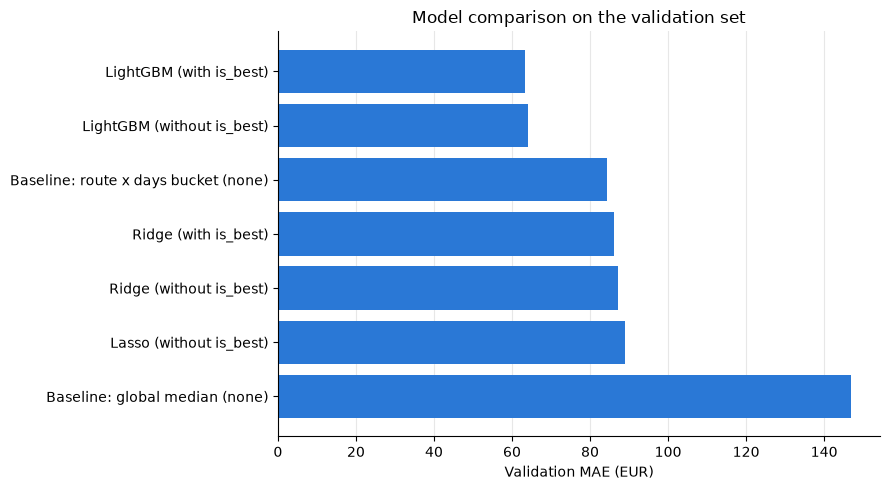

In [46]:
val_sorted = val_table.sort_values("MAE (EUR)", ascending=False)

labels = []
for index, row in val_sorted.iterrows():
    labels.append(f"{row['model']} ({row['feature set']})")

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(labels, val_sorted["MAE (EUR)"], color=BAR_COLOR)
ax.set_xlabel("Validation MAE (EUR)")
ax.set_title("Model comparison on the validation set")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

### 8.1 Feature set for the analysis

- `"without is_best"` is the safer choice: `is_best` is partly computed by Google from the price, so a model that relies on it is partly "looking at the answer", which is probably why the results are a bit better. It also might not be available for the user when searching flights, so it is safer to not take "is_best" into account.

In [47]:
ANALYSIS_FEATURE_SET = "without is_best"

ANALYSIS_MODELS = []
for model_name in ["Ridge", "Lasso", "LightGBM"]:
    ANALYSIS_MODELS.append(f"{model_name} ({ANALYSIS_FEATURE_SET})")

ANALYSIS_COLUMNS = get_all_columns(ANALYSIS_FEATURE_SET)
print(ANALYSIS_MODELS)

['Ridge (without is_best)', 'Lasso (without is_best)', 'LightGBM (without is_best)']


## 9. Error analysis by segment

The overall MAE hides where a model is good or bad. Here we look at the validation errors per segment:
- days to departure (bucket),
- airline (the 12 airlines with the most rows),
- route (the 12 routes with the most rows).

We also add the route baseline for reference.

### 9.1 Errors per row

In [48]:
errors = val[["dtd_bucket", "airline", "route", "price"]].copy()

errors["Baseline: route x days bucket"] = baseline_val_prediction - price_val
for key in ANALYSIS_MODELS:
    errors[key] = val_predictions[key] - price_val

ERROR_COLUMNS = ["Baseline: route x days bucket"] + ANALYSIS_MODELS
errors.head()

,dtd_bucket,airline,route,price,Baseline: route x days bucket,Ridge (without is_best),Lasso (without is_best),LightGBM (without is_best)
16155618,0-7,Wizz Air,VNO-TLL,69.989998,76.590004,-25.423188,-24.009118,-25.627579
16155619,0-7,Wizz Air,TLL-VNO,69.989998,96.230003,-19.227624,-20.195505,-28.884847
16155620,0-7,Air Baltic,TLL-VNO,115.220001,51.000000,-26.400525,-23.837158,6.276468
16155621,0-7,Air Baltic,VNO-RIX,106.580002,-14.000000,-38.065207,-16.428478,13.880647
16155622,0-7,Air Baltic,VNO-RIX,106.580002,-14.000000,-36.423853,-16.428478,11.096693


A positive error means the model predicted too high, a negative error means too low.

### 9.2 Predicted vs actual price

Each dot is one validation row (a random 20,000 rows are plotted). A perfect model would put every dot on the dashed diagonal. Both axes are logarithmic, otherwise the cheap tickets would all be squeezed into one corner.

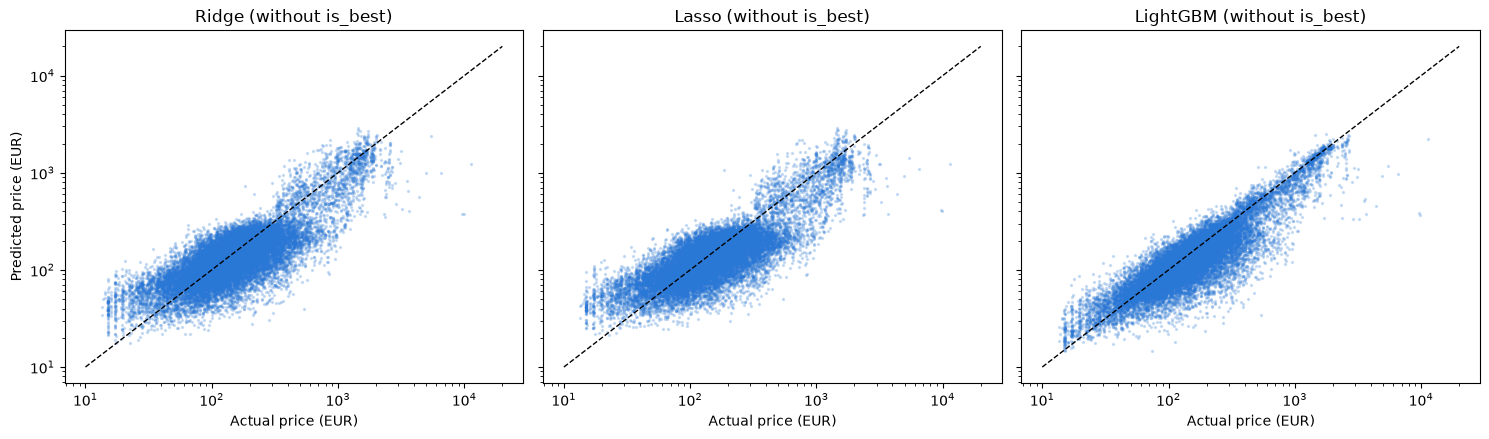

In [49]:
plot_rows = errors.sample(n=min(20000, len(errors)), random_state=RANDOM_STATE)

fig, axes = plt.subplots(1, len(ANALYSIS_MODELS), figsize=(15, 4.5), sharex=True, sharey=True)

for ax, key in zip(axes, ANALYSIS_MODELS):
    predicted = plot_rows["price"] + plot_rows[key]
    ax.scatter(plot_rows["price"], predicted, s=2, alpha=0.2, color=BAR_COLOR)
    ax.plot([10, 20000], [10, 20000], color="black", linestyle="--", linewidth=1)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_title(key)
    ax.set_xlabel("Actual price (EUR)")

axes[0].set_ylabel("Predicted price (EUR)")
plt.tight_layout()
plt.show()

### 9.3 MAE per segment

For each segment we compute the mean **absolute** error per model and plot them side by side.

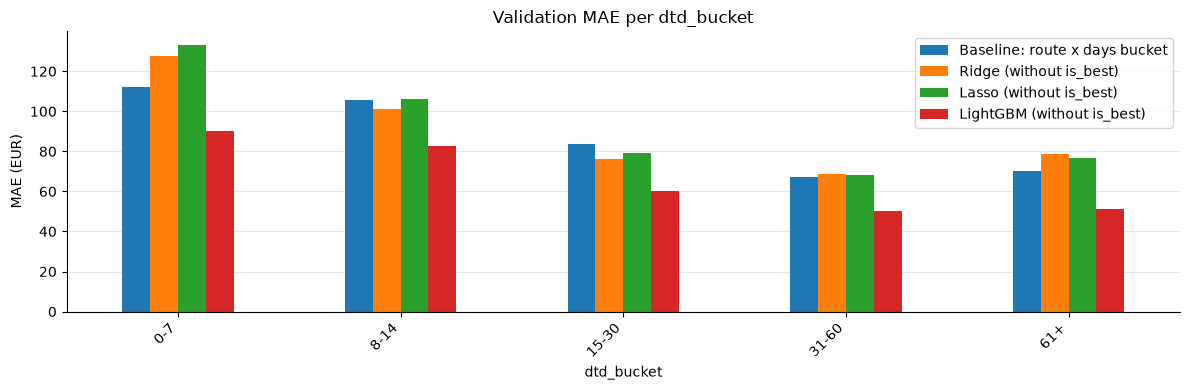

,Baseline: route x days bucket,Ridge (without is_best),Lasso (without is_best),LightGBM (without is_best),rows
dtd_bucket,,,,,
0-7,112.000000,127.5,133.3,90.1,359264
8-14,105.500000,101.1,106.3,82.9,222453
15-30,83.500000,76.2,79.0,60.5,459993
31-60,67.099998,68.8,68.3,50.4,478605
61+,70.000000,78.9,76.7,51.3,431244


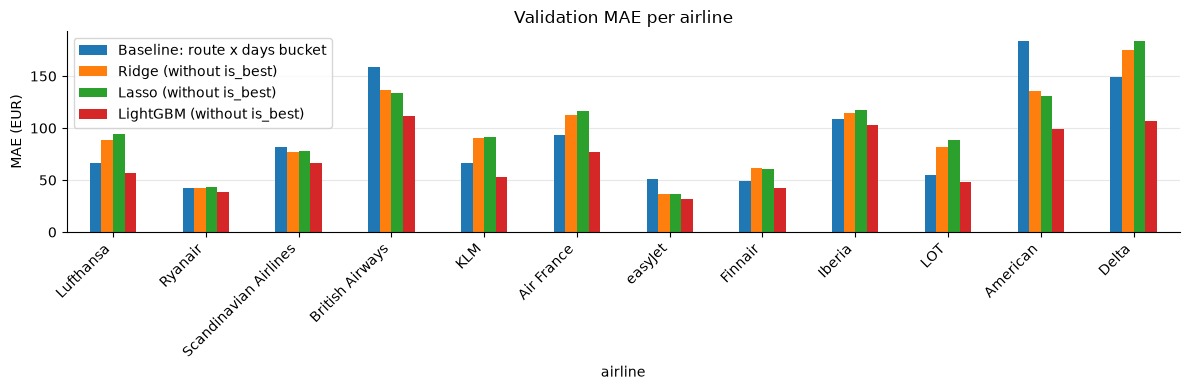

,Baseline: route x days bucket,Ridge (without is_best),Lasso (without is_best),LightGBM (without is_best),rows
airline,,,,,
Lufthansa,66.099998,88.9,94.7,56.7,202483
Ryanair,42.599998,42.7,42.9,38.7,157093
Scandinavian Airlines,81.500000,77.4,77.8,66.4,140517
British Airways,158.800003,136.8,134.2,111.2,136585
KLM,66.199997,90.4,91.7,53.2,126703
Air France,93.300003,112.9,116.6,77.3,109779
easyJet,50.599998,36.4,36.8,31.7,87984
Finnair,49.099998,61.7,60.9,42.3,77686
Iberia,108.699997,114.2,117.6,103.3,73505


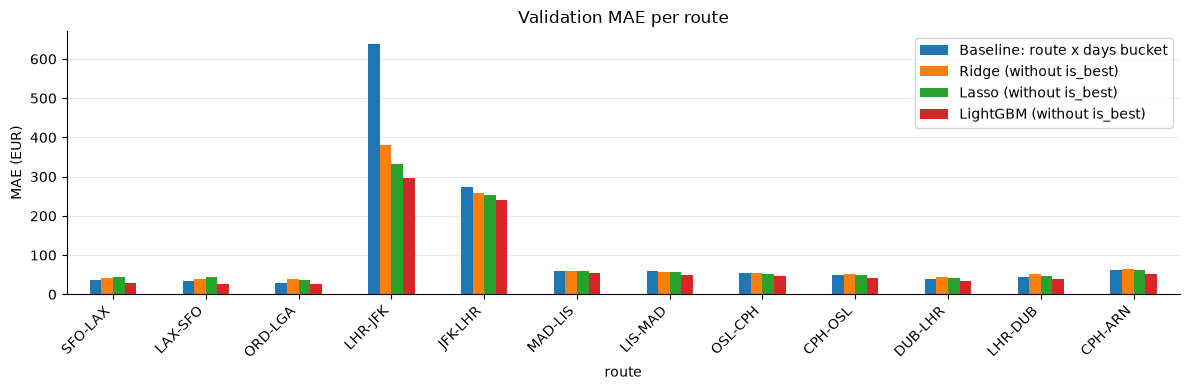

,Baseline: route x days bucket,Ridge (without is_best),Lasso (without is_best),LightGBM (without is_best),rows
route,,,,,
SFO-LAX,35.599998,41.7,44.1,29.0,15779
LAX-SFO,35.000000,40.4,43.1,27.0,15530
ORD-LGA,29.900000,38.4,35.6,26.1,14205
LHR-JFK,638.500000,380.9,332.9,296.8,10778
JFK-LHR,274.600006,257.5,253.7,239.8,10769
MAD-LIS,60.599998,59.3,59.1,55.0,10076
LIS-MAD,60.400002,57.1,58.0,49.2,10056
OSL-CPH,53.599998,54.4,52.5,46.8,9471
CPH-OSL,50.099998,50.6,48.6,41.5,9466


In [50]:
def mae_per_segment(segment_column, top_n=None):
    absolute_errors = errors[[segment_column]].copy()
    for column in ERROR_COLUMNS:
        absolute_errors[column] = errors[column].abs()

    table = absolute_errors.groupby(segment_column, observed=True)[ERROR_COLUMNS].mean()
    table["rows"] = absolute_errors.groupby(segment_column, observed=True).size()

    if top_n is not None:
        table = table.sort_values("rows", ascending=False).head(top_n)
    return table


for segment_column, top_n in [("dtd_bucket", None), ("airline", 12), ("route", 12)]:
    table = mae_per_segment(segment_column, top_n)

    fig, ax = plt.subplots(figsize=(12, 4))
    table[ERROR_COLUMNS].plot(kind="bar", ax=ax)
    ax.set_title(f"Validation MAE per {segment_column}")
    ax.set_ylabel("MAE (EUR)")
    ax.set_xlabel(segment_column)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

    display(table.round(1))

### 9.4 Bias per days-to-departure bucket

MAE tells how big the errors are, but not their direction. The mean (signed) error per bucket shows whether a model systematically predicts too high or too low, for example for last-minute flights. We can see that every model low-balls the price. This is because we trained on log(price) and removed outliers.

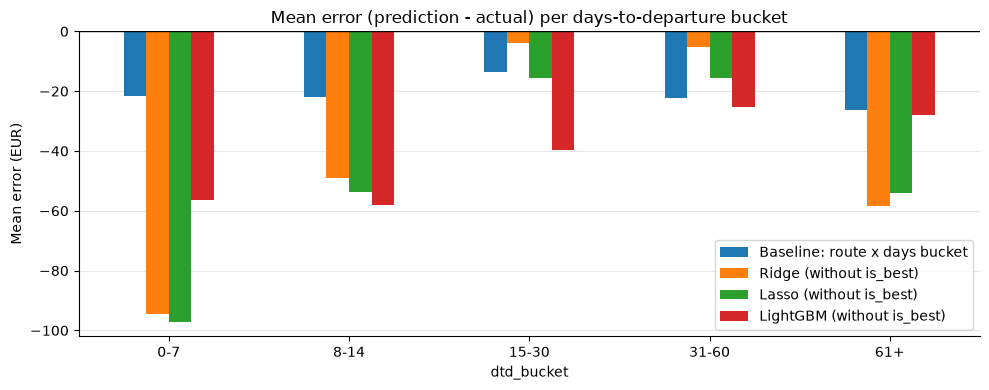

,Baseline: route x days bucket,Ridge (without is_best),Lasso (without is_best),LightGBM (without is_best)
dtd_bucket,,,,
0-7,-21.600000,-94.5,-97.2,-56.5
8-14,-21.900000,-49.0,-53.8,-58.2
15-30,-13.600000,-3.9,-15.7,-39.7
31-60,-22.299999,-5.4,-15.5,-25.4
61+,-26.400000,-58.5,-54.2,-27.9


In [51]:
bias_table = errors.groupby("dtd_bucket", observed=True)[ERROR_COLUMNS].mean()

fig, ax = plt.subplots(figsize=(10, 4))
bias_table.plot(kind="bar", ax=ax)
ax.axhline(0, color="black", linewidth=1)
ax.set_title("Mean error (prediction - actual) per days-to-departure bucket")
ax.set_ylabel("Mean error (EUR)")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

bias_table.round(1)

## 10. Feature importance

Which features does each model rely on? The models measure importance in different ways, so we look at each one separately first and then put them side by side (10.4):

| measure | models | what it means |
|---|---|---|
| coefficients | Ridge, Lasso | effect on `log_price` of one unit (numeric: one standard deviation) or of one category |
| gain | LightGBM | how much the trees' splits on a feature reduced the error |

Lasso was only trained on the "without is_best" feature set (section 6.3), so this section only works with `ANALYSIS_FEATURE_SET = "without is_best"`.

### 10.1 Linear model coefficients

After one-hot encoding there is one coefficient per *category* (e.g. one per airline). To connect each coefficient back to its original column, we build a list `original_feature` in the same order as the columns of the encoded matrix: first the numeric columns, then, per categorical column, one entry per category.

A coefficient is on the `log_price` scale: a coefficient of 0.1 means about +10% price.

In [52]:
def get_coefficient_table(pipeline, feature_set):
    preprocess = pipeline.named_steps["preprocess"]
    encoder = preprocess.named_transformers_["onehot"]
    coefficients = pipeline.named_steps["model"].coef_

    feature_names = []
    original_feature = []

    for column in get_numeric_columns(feature_set):
        feature_names.append(column)
        original_feature.append(column)

    onehot_columns = CATEGORICAL_FEATURES + SMALL_INTEGER_FEATURES
    for column, categories in zip(onehot_columns, encoder.categories_):
        for category in categories:
            feature_names.append(f"{column} = {category}")
            original_feature.append(column)

    table = pd.DataFrame({
        "feature": feature_names,
        "original feature": original_feature,
        "coefficient": coefficients,
    })
    table["abs coefficient"] = table["coefficient"].abs()
    return table


coefficient_tables = {}
for model_name in ["Ridge", "Lasso"]:
    key = f"{model_name} ({ANALYSIS_FEATURE_SET})"
    coefficient_tables[model_name] = get_coefficient_table(best_models[key], ANALYSIS_FEATURE_SET)

coefficient_tables["Ridge"].head()

,feature,original feature,coefficient,abs coefficient
0,distance_km,distance_km,0.258786,0.258786
1,travel_time,travel_time,0.198858,0.198858
2,emissions,emissions,0.059795,0.059795
3,emissions_per_km,emissions_per_km,-0.015215,0.015215
4,days_to_departure,days_to_departure,-0.219497,0.219497


In [55]:
coefficient_tables["Ridge"].head(15)

,feature,original feature,coefficient,abs coefficient
0,distance_km,distance_km,0.258786,0.258786
1,travel_time,travel_time,0.198858,0.198858
2,emissions,emissions,0.059795,0.059795
3,emissions_per_km,emissions_per_km,-0.015215,0.015215
4,days_to_departure,days_to_departure,-0.219497,0.219497
5,dep_is_weekend,dep_is_weekend,0.034389,0.034389
6,is_christmas,is_christmas,0.036501,0.036501
7,is_new_year,is_new_year,0.049150,0.049150
8,is_summer,is_summer,0.066402,0.066402
9,region_from = Baltics,region_from,-0.063696,0.063696


The 15 largest coefficients (by absolute value) for Ridge and Lasso. Positive = makes the ticket more expensive, negative = cheaper.

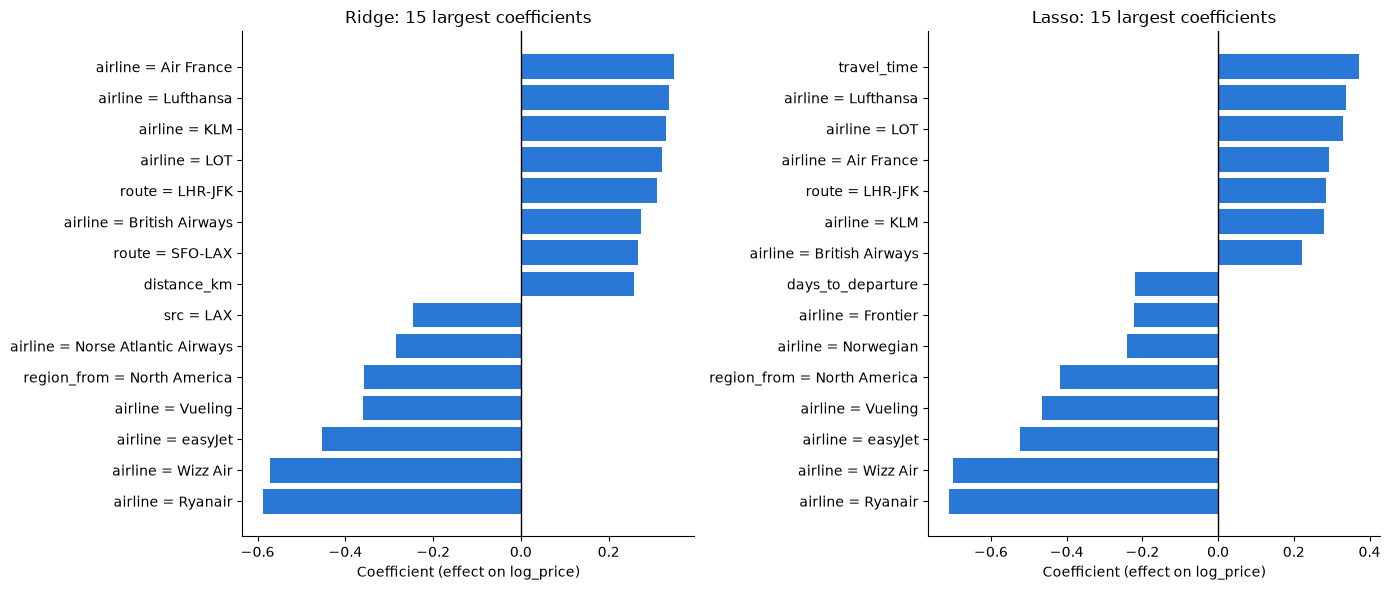

In [53]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, model_name in zip(axes, ["Ridge", "Lasso"]):
    top = coefficient_tables[model_name].sort_values("abs coefficient", ascending=False).head(15)
    top = top.sort_values("coefficient")
    ax.barh(top["feature"], top["coefficient"], color=BAR_COLOR)
    ax.axvline(0, color="black", linewidth=1)
    ax.set_title(f"{model_name}: 15 largest coefficients")
    ax.set_xlabel("Coefficient (effect on log_price)")
    ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

Coefficients of the numeric features only. These are directly comparable with each other, because all numeric features were scaled to standard deviation 1. With highly correlated features (distance, travel time, emissions) Ridge tends to spread the effect over all of them, while Lasso tends to keep one and shrink the others.

In [54]:
numeric_columns = get_numeric_columns(ANALYSIS_FEATURE_SET)
numeric_coefficients = pd.DataFrame(index=numeric_columns)

for model_name in ["Ridge", "Lasso"]:
    table = coefficient_tables[model_name].set_index("feature")
    numeric_coefficients[model_name] = table.loc[numeric_columns, "coefficient"]

numeric_coefficients.round(4)

,Ridge,Lasso
distance_km,0.2588,0.1477
travel_time,0.1989,0.3735
emissions,0.0598,0.0123
emissions_per_km,-0.0152,0.0000
days_to_departure,-0.2195,-0.2186
dep_is_weekend,0.0344,0.0165
is_christmas,0.0365,0.0367
is_new_year,0.0491,0.0481
is_summer,0.0664,0.0630


### 10.2 Features removed by Lasso

Lasso sets some coefficients to exactly zero. For each original column we count how many of its encoded columns (categories) were set to zero. A column where all categories are zero was removed completely by Lasso.

In [56]:
lasso_table = coefficient_tables["Lasso"]
lasso_table["is zero"] = lasso_table["coefficient"] == 0

zero_summary = lasso_table.groupby("original feature").agg(
    encoded_columns=("is zero", "size"),
    zero_columns=("is zero", "sum"),
)
zero_summary["share zero"] = (zero_summary["zero_columns"] / zero_summary["encoded_columns"]).round(3)
zero_summary = zero_summary.sort_values("share zero", ascending=False)

print(f"Lasso set {lasso_table['is zero'].sum():,} of {len(lasso_table):,} coefficients to zero.")
zero_summary

Lasso set 1,231 of 1,358 coefficients to zero.


,encoded_columns,zero_columns,share zero
original feature,,,
emissions_per_km,1,1,1.000
search_weekday,7,7,1.000
search_hour,16,16,1.000
route,1079,1074,0.995
dst,53,39,0.736
src,47,31,0.660
aircraft,37,20,0.541
region_to,8,4,0.500
airline,51,21,0.412


In [57]:
fully_removed = zero_summary[zero_summary["share zero"] == 1].index

print("Columns removed completely by Lasso:")
if len(fully_removed) == 0:
    print("  none")
for column in fully_removed:
    print("  -", column)

Columns removed completely by Lasso:
  - emissions_per_km
  - search_weekday
  - search_hour


### 10.3 LightGBM: gain importance

Gain is the total reduction in error from all splits on a feature. It is shown as a share of the total, so the bars add up to 100%.

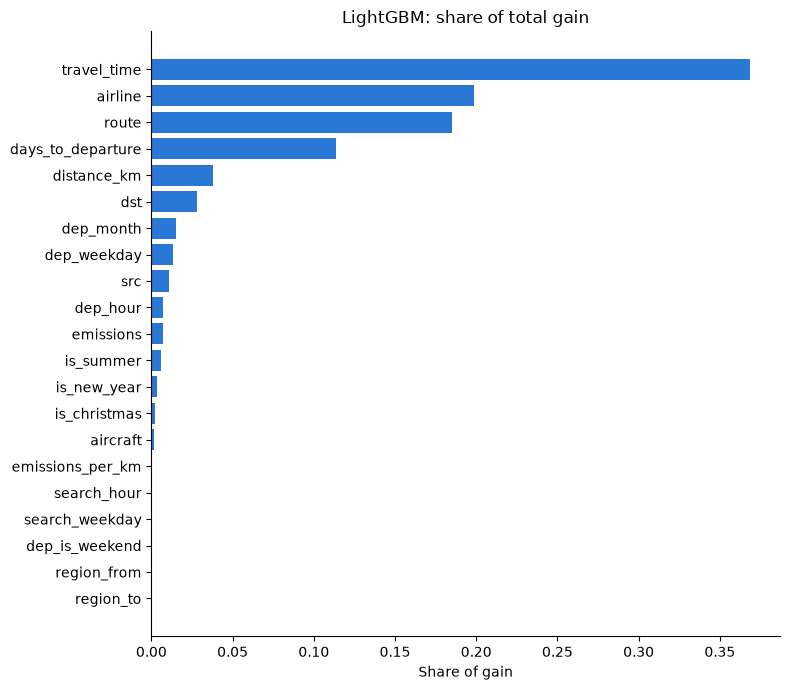

In [58]:
lgbm_model = best_models[f"LightGBM ({ANALYSIS_FEATURE_SET})"]

gain = lgbm_model.booster_.feature_importance(importance_type="gain")
gain_importance = pd.Series(gain, index=ANALYSIS_COLUMNS)
gain_importance = gain_importance / gain_importance.sum()
gain_importance = gain_importance.sort_values()

fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(gain_importance.index, gain_importance.values, color=BAR_COLOR)
ax.set_title("LightGBM: share of total gain")
ax.set_xlabel("Share of gain")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

### 10.4 Side-by-side comparison

One row per original feature, with one importance number per model:

- **Ridge and Lasso:** the sum of the absolute coefficients of all encoded columns that belong to the feature. For a numeric feature that is just its one coefficient. For `airline` it is the sum over all airline columns.
- **LightGBM:** the share of the total gain from 10.3.
- **Lasso share zero** from 10.2, for reference.

The numbers have different units, so they cannot be compared directly between models. That is why we also add the rank of each feature per model (1 = most important). Features with similar ranks in all models are robust drivers of price; big differences show where the models "think" differently.

Keep in mind that summing coefficients favours features with many categories: `route` has about 1,100 one-hot columns, so its sum can be large even if every single route coefficient is small.

In [59]:
comparison = pd.DataFrame(index=ANALYSIS_COLUMNS)

for model_name in ["Ridge", "Lasso"]:
    table = coefficient_tables[model_name]
    summed = table.groupby("original feature")["abs coefficient"].sum()
    comparison[f"{model_name} sum |coef|"] = summed

comparison["LightGBM gain share"] = gain_importance
comparison["Lasso share zero"] = zero_summary["share zero"]

IMPORTANCE_COLUMNS = ["Ridge sum |coef|", "Lasso sum |coef|", "LightGBM gain share"]
for column in IMPORTANCE_COLUMNS:
    comparison[f"rank {column}"] = comparison[column].rank(ascending=False, method="min").astype(int)

comparison = comparison.sort_values("rank LightGBM gain share")
comparison.round(4)

,Ridge sum |coef|,Lasso sum |coef|,LightGBM gain share,Lasso share zero,rank Ridge sum |coef|,rank Lasso sum |coef|,rank LightGBM gain share
travel_time,0.1989,0.3735,0.3686,0.000,14,9,1
airline,8.0486,5.7134,0.1985,0.412,2,1,2
route,38.5789,0.4476,0.1849,0.995,1,8,3
days_to_departure,0.2195,0.2186,0.1135,0.000,13,11,4
distance_km,0.2588,0.1477,0.0379,0.000,12,13,5
dst,2.8204,0.8614,0.0278,0.736,3,4,6
dep_month,0.9225,0.5871,0.0154,0.333,8,7,7
dep_weekday,0.3612,0.3124,0.0131,0.286,9,10,8
src,2.6153,1.2548,0.0108,0.660,4,2,9
dep_hour,1.1901,0.6439,0.0074,0.375,6,6,10


The same comparison as a chart. To put the three models on one axis, each model's numbers are divided by their total, so every model's bars add up to 1 (a "share of importance").

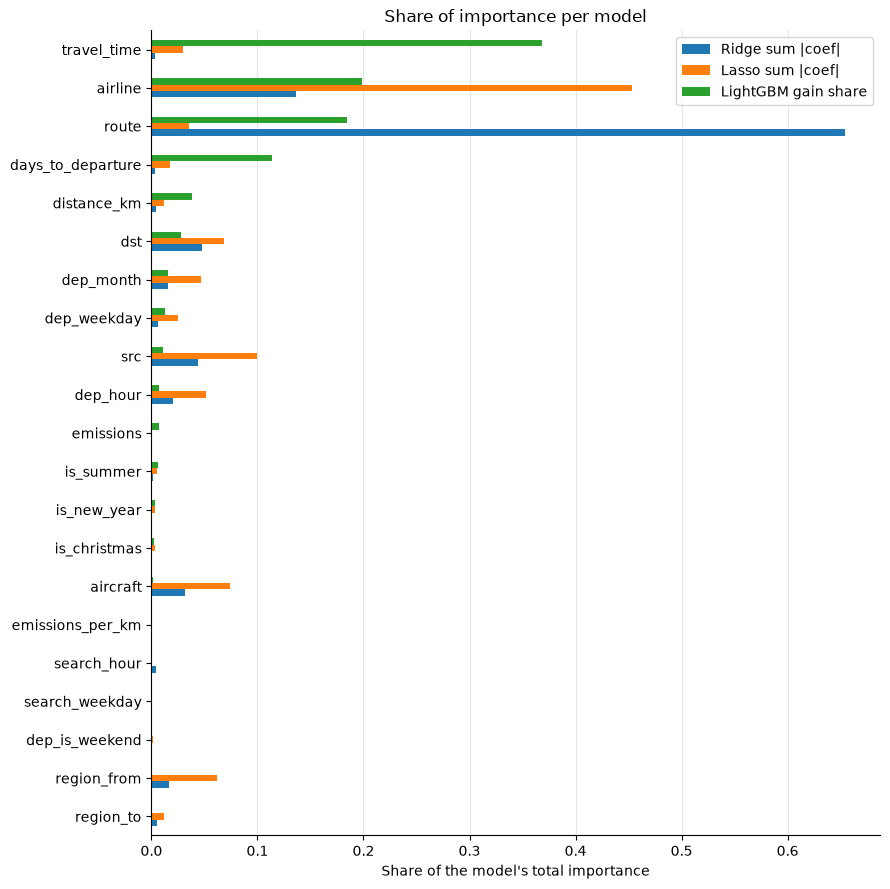

In [60]:
share_table = pd.DataFrame(index=comparison.index)
for column in IMPORTANCE_COLUMNS:
    share_table[column] = comparison[column] / comparison[column].sum()

share_table = share_table.sort_values("LightGBM gain share")

fig, ax = plt.subplots(figsize=(9, 9))
share_table.plot(kind="barh", ax=ax)
ax.set_title("Share of importance per model")
ax.set_xlabel("Share of the model's total importance")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

## 11. Partial dependence plots

A partial dependence plot shows how the average prediction changes when one feature is changed while everything else stays as in the data. It answers questions like "how does the predicted price change as departure gets closer?".

- For Ridge the curve is a straight line for scaled numeric features, and a step pattern for one-hot features.
- For LightGBM the curve can have any shape.

The y-axis is the predicted `log_price`. We use 5,000 random validation rows, because a PDP makes many predictions.

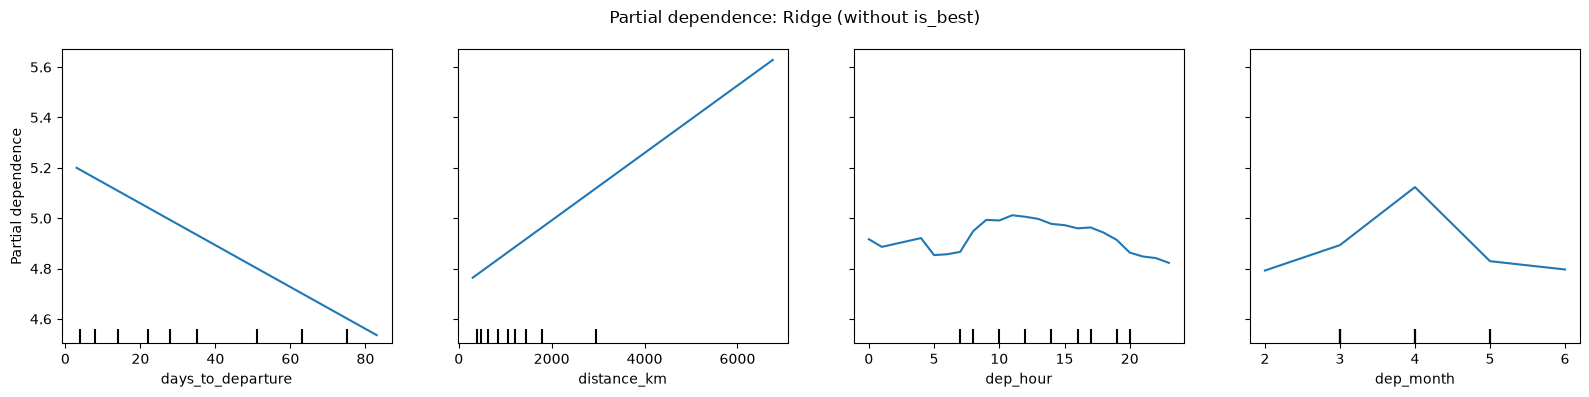

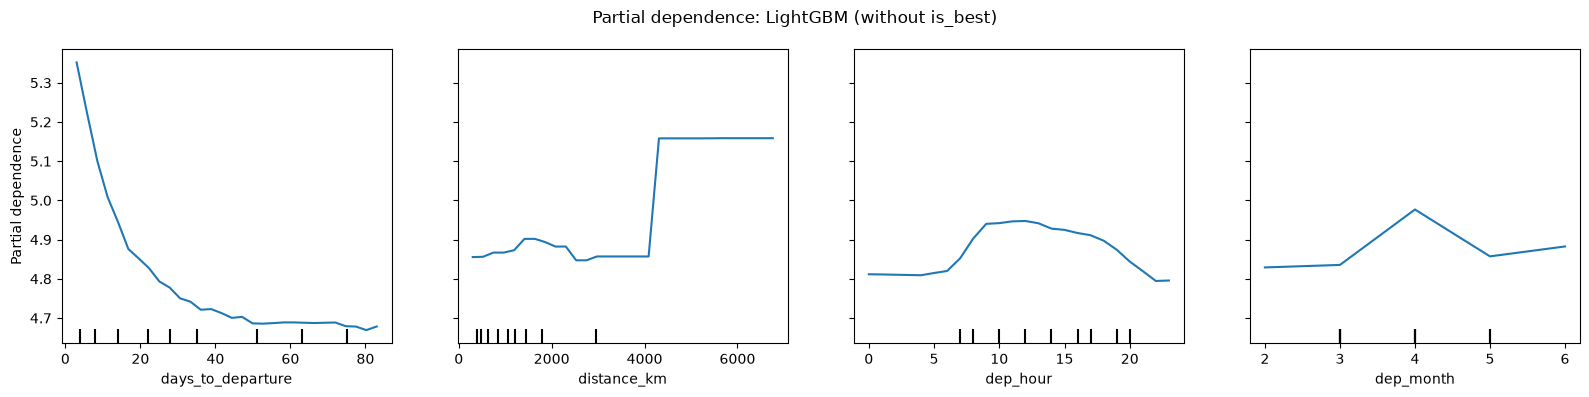

In [61]:
PDP_FEATURES = ["days_to_departure", "distance_km", "dep_hour", "dep_month"]
pdp_rows = val[ANALYSIS_COLUMNS].sample(n=min(5000, len(val)), random_state=RANDOM_STATE).copy()

# scikit-learn only draws PDPs for float columns, so the plotted columns are converted to float
for column in PDP_FEATURES:
    pdp_rows[column] = pdp_rows[column].astype("float64")

for key in [f"Ridge ({ANALYSIS_FEATURE_SET})", f"LightGBM ({ANALYSIS_FEATURE_SET})"]:
    fig, ax = plt.subplots(figsize=(16, 4))
    PartialDependenceDisplay.from_estimator(
        best_models[key],
        pdp_rows,
        features=PDP_FEATURES,
        kind="average",
        grid_resolution=30,
        n_cols=len(PDP_FEATURES),
        ax=ax,
    )
    fig.suptitle(f"Partial dependence: {key}")
    plt.tight_layout()
    plt.show()

## 12. Final evaluation on the test set

Now that all choices are made (hyperparameters, feature sets), every model is evaluated once on the test set.

The models are the ones trained on the training split with the hyperparameters chosen on validation.

In [62]:
add_result("Baseline: global median", "none", "test",
           price_test, np.full(len(price_test), global_median))
add_result("Baseline: route x days bucket", "none", "test",
           price_test, predict_route_bucket_baseline(test))

for model_name in ["Ridge", "Lasso", "LightGBM"]:
    for feature_set in FEATURE_SETS:
        if model_name == "Lasso" and feature_set == "with is_best":
            continue
            
        model = best_models[f"{model_name} ({feature_set})"]

        if model_name == "LightGBM":
            prediction = model.predict(X_test[get_all_columns(feature_set)])
        else:
            prediction = model.predict(X_test)

        add_result(model_name, feature_set, "test", price_test, np.exp(prediction))

Baseline: global median none test  MAE 159.33   RMSE 352.93
Rows that needed a fallback: 0.33%
Baseline: route x days bucket none test  MAE 87.81   RMSE 203.83
Ridge with is_best test  MAE 81.91   RMSE 182.57
Ridge without is_best test  MAE 83.45   RMSE 185.97
Lasso without is_best test  MAE 88.04   RMSE 196.55
LightGBM with is_best test  MAE 74.67   RMSE 189.84
LightGBM without is_best test  MAE 75.28   RMSE 190.76


Validation and test results side by side. The gap between the two columns shows how much the validation score was helped by flights that were already seen in train.

In [63]:
results_table = pd.DataFrame(results)

final_table = results_table.pivot_table(
    index=["model", "feature set"],
    columns="split",
    values=["MAE (EUR)", "RMSE (EUR)"],
)
final_table = final_table[[("MAE (EUR)", "val"), ("MAE (EUR)", "test"),
                           ("RMSE (EUR)", "val"), ("RMSE (EUR)", "test")]]
final_table.sort_values(("MAE (EUR)", "test"))

MAE (EUR)         RMSE (EUR)  \
split                                               val    test        val   
model                         feature set                                    
LightGBM                      with is_best        63.31   74.67     195.96   
                              without is_best     63.99   75.28     196.69   
Ridge                         with is_best        86.25   81.91     219.84   
                              without is_best     87.27   83.45     221.49   
Baseline: route x days bucket none                84.25   87.81     229.24   
Lasso                         without is_best     88.98   88.04     226.20   
Baseline: global median       none               146.97  159.33     348.28   

                                                       
split                                            test  
model                         feature set              
LightGBM                      with is_best     189.84  
                              without is_best  190.76  
Ridge                         with is_best     182.57  
                              without is_best  185.97  
Baseline: route x days bucket none             203.83  
Lasso                         without is_best  196.55  
Baseline: global median       none             352.93

As we can see, the gap between LightGBM and Ridge got smaller, as LightGBM caught on to specific patterns more in the training set, which do not help to generalize and caused it to get worse results on the test set. Ridge was more general, improving on the test set, but was still not as good as LightGBM.

## 12.1 Lets plot the results on the test set.

As we can see, we didn't beat the baseline by much, but LightGBM still came out on top.

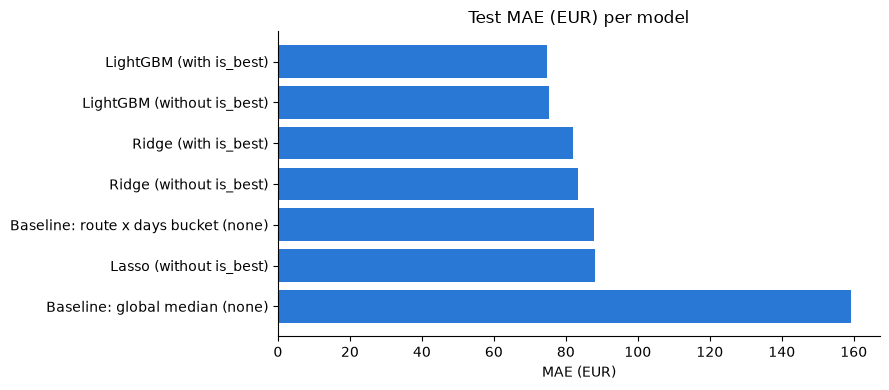

,name,MAE (EUR),RMSE (EUR)
12,LightGBM (with is_best),74.67,189.84
13,LightGBM (without is_best),75.28,190.76
9,Ridge (with is_best),81.91,182.57
10,Ridge (without is_best),83.45,185.97
8,Baseline: route x days bucket (none),87.81,203.83
11,Lasso (without is_best),88.04,196.55
7,Baseline: global median (none),159.33,352.93


In [67]:
results_table = pd.DataFrame(results)
test_results = results_table[results_table["split"] == "test"].copy()
test_results["name"] = test_results["model"] + " (" + test_results["feature set"] + ")"
test_results = test_results.sort_values("MAE (EUR)")

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(test_results["name"], test_results["MAE (EUR)"], color=BAR_COLOR)
ax.invert_yaxis()
ax.set_title("Test MAE (EUR) per model")
ax.set_xlabel("MAE (EUR)")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

test_results[["name", "MAE (EUR)", "RMSE (EUR)"]]

## 12.2 Lets also check whether the models low-ball the price overall or not

Rows that needed a fallback: 0.33%


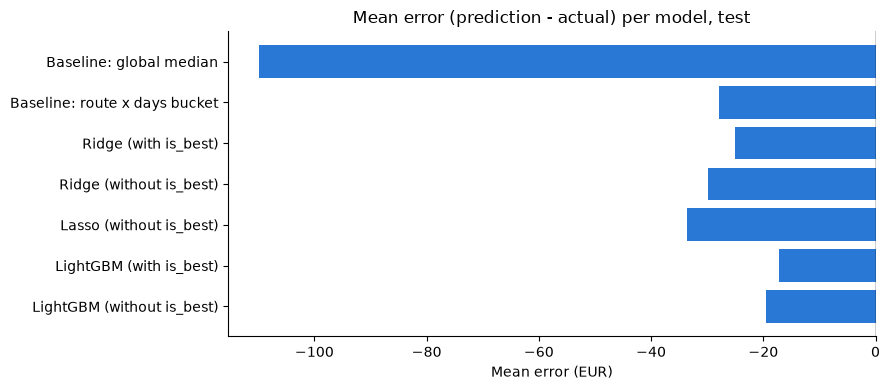

Baseline: global median         -109.9
Baseline: route x days bucket    -28.0
Ridge (with is_best)             -25.1
Ridge (without is_best)          -29.9
Lasso (without is_best)          -33.5
LightGBM (with is_best)          -17.1
LightGBM (without is_best)       -19.4
dtype: float64

In [65]:
test_bias = {}

test_bias["Baseline: global median"] = (global_median - price_test).mean()
test_bias["Baseline: route x days bucket"] = (predict_route_bucket_baseline(test) - price_test).mean()

for model_name in ["Ridge", "Lasso", "LightGBM"]:
    for feature_set in FEATURE_SETS:
        if model_name == "Lasso" and feature_set == "with is_best":
            continue

        model = best_models[f"{model_name} ({feature_set})"]

        if model_name == "LightGBM":
            prediction = model.predict(X_test[get_all_columns(feature_set)])
        else:
            prediction = model.predict(X_test)

        predicted_price = np.exp(prediction)
        test_bias[f"{model_name} ({feature_set})"] = (predicted_price - price_test).mean()

test_bias = pd.Series(test_bias)

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(test_bias.index, test_bias.values, color=BAR_COLOR)
ax.axvline(0, color="black", linewidth=1)
ax.invert_yaxis()
ax.set_title("Mean error (prediction - actual) per model, test")
ax.set_xlabel("Mean error (EUR)")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

test_bias.round(1)

All models low-ball the price, but LightGBM does it the least, only 17-19 EUR cheaper than the actual price.

## 13. Conclusions

**Model comparison**
- Best model and its test MAE / RMSE: LightGBM with is_best - test MAE: 74.67 EUR, RMSE: 189.84
- Improvement over the route x days-to-departure baseline: 13.14 EUR closer to the actual price on average than the baseline
- Ridge vs Lasso vs LightGBM: LightGBM got the best MAE, but Ridge got the best RMSE. This means LightBGM's mistakes are smaller on average and fewer than Ridge, but a few misses are bigger than Ridge ever makes, which RMSE amplifies.

**Effect of `is_best`**
- Difference in MAE with and without `is_best`: LightGBM only benefits about 1.5 EUR on preditions with is_best
- Decision: It is safer to use models without it, because this is derived from price data, which an user would not have during predictions and it doesn't give much benefit anyway.

**Where the models struggle**
- Days-to-departure buckets / airlines / routes with the largest errors: All models usually produce more errors when the flight gets closer to departure, so last minute predictions are not accurate. Some airlines like American and Delta are hard to predict for the models, while some are easier. Routes including JFK contain way bigger errors than other routes.
- Systematic under-prediction: Because we trained on log(price) to make the expensive tickets affect our predictions less and favor cheaper tickets which make up a huge chunk of our dataset, the models tend to low-ball the prices.

**Feature importance**
- Features that are important in all models: airline, route, travel time
- Features Lasso removed: emissions_per_km, search_weekday, search_hour
- Effect of days to departure on price: The farther out the flight is from departure, the cheaper the ticket. The relationship is not linear, the price grows exponentially as the departure date gets closer. This relationship was missed by Ridge and Lasso.

**Validation vs test**
- The validation set was more optimistic for LightGBM, because it tended to learn the finer relationships in the flights, as validation and train sets overlapped by flights more than train and test. This made Ridge generalize a little bit better, but it's average mistake was still bigger.

**Limitations**
- The split was made by time and the timeframe was about 1 year, so seasonal effects couldn't be learned effectively.
- The models low-ball on average, so when the model predicts a small decrease in price, it might not be correct.
- Time and resources for training and tuning were limited, so the models were not retrained on test+val and parameters were not the most optimal.
- Not many routes are covered, so this model does not generalize well on unseen routes most probably
- By varying days_to_departure for a given flight, the model can estimate how the expected price changes closer to departure, which supports a buy-now-or-wait decision. However, this reflects average patterns learned across flights, and small predicted differences fall within the model's error.